# Step 9 - Network core and the Phase A hypotheses

Uses the CV of step 8 and the runs of step 7. Logic: `src/core.py`, `src/analysis.py`.

- **important** = in the top 10 % of the method's base ranking (1,971 papers)
- **Phase A core rule** (as written): stable = CV <= 10th percentile of *all* papers' CV
- **adjusted core rule** (D16): stable = CV <= median CV of the *important* papers
- **stay in top** = share of the 30 runs in which a paper is still in the top 10 %

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('Final-Project'):
    !git clone https://github.com/ShaharBar99/Final-Project.git
    %cd Final-Project
    !pip install -q -r requirements.txt
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import analysis, core, ranking

per_run, cv_table, profiles, cvs = analysis.evaluate_all()
summary, cores = analysis.core_analysis(cvs)
summary.to_csv(analysis.TABLES_DIR / 'core_summary.csv', index=False)
order = ['rf_without_pagerank', 'rf_with_pagerank', 'pagerank', 'closeness', 'degree', 'kcore', 'betweenness']
def show(col, digits=3):
    return summary.pivot_table(index='method', columns=['kind', 'level'], values=col).loc[order].round(digits)

## 1. The Phase A core rule, as written

Core size (papers that are both important and have CV <= 10th percentile of all papers):

In [3]:
show('phaseA_core_size', 0)

kind                add_dag                 add_random                 remove  \
level                  0.05    0.10    0.20       0.05    0.10    0.20   0.05   
method                                                                          
rf_without_pagerank   227.0   292.0   372.0       75.0   963.0  1333.0    0.0   
rf_with_pagerank        5.0     4.0     5.0      416.0   432.0   311.0    0.0   
pagerank                1.0     3.0    19.0      429.0   705.0   918.0    0.0   
closeness             104.0   459.0   886.0     1409.0  1845.0  1803.0    0.0   
degree               1678.0  1730.0  1746.0     1692.0  1714.0  1737.0    0.0   
kcore                1284.0  1245.0  1113.0     1414.0  1214.0  1099.0  295.0   
betweenness             0.0   310.0  1007.0      888.0  1227.0  1435.0    0.0   

kind                                 
level                  0.10    0.20  
method                               
rf_without_pagerank     0.0     0.0  
rf_with_pagerank        0.0     3.0  
pagerank                0.0     0.0  
closeness               0.0     0.0  
degree               1408.0  1624.0  
kcore                 516.0  1113.0  
betweenness             0.0     0.0

Average base rank of the papers this rule calls *stable* (19,717 = bottom of the ranking):

In [4]:
show('phaseA_stable_mean_base_rank', 0)

kind                 add_dag                   add_random                   \
level                   0.05     0.10     0.20       0.05    0.10     0.20   
method                                                                       
rf_without_pagerank  13711.0  13325.0  12423.0    13494.0  4401.0   2250.0   
rf_with_pagerank     16153.0  14033.0  13933.0     8533.0  9630.0  10588.0   
pagerank             15193.0  13633.0  13133.0     8412.0  6167.0   4615.0   
closeness            14139.0  10073.0   6821.0     4194.0  1038.0   1039.0   
degree                1200.0   1043.0   1033.0     1155.0  1053.0   1037.0   
kcore                 3235.0   2378.0   1937.0     3141.0  2471.0   2000.0   
betweenness          10762.0   9116.0   5575.0     6238.0  4540.0   3508.0   

kind                  remove                    
level                   0.05     0.10     0.20  
method                                          
rf_without_pagerank  16837.0  18164.0  18678.0  
rf_with_pagerank     18694.0  18694.0  18667.0  
pagerank             18678.0  18694.0  18694.0  
closeness            18683.0  18694.0  18694.0  
degree               14632.0   3774.0   1219.0  
kcore                10313.0   6728.0   2748.0  
betweenness          10762.0  10762.0  10762.0

**Finding.** Under edge removal the rule finds no core at all for the forest, PageRank and closeness. The 10th-percentile threshold is 0: more than 10 % of the papers never change their score, and they are papers at the very bottom (mean base rank ~18,700 of 19,717). The rule as written measures 'stable periphery', not 'stable importance'. That is why the adjusted rule judges stability among the important papers.

## 2. Do the important papers stay important? (H3, question 4)

Share of runs in which an important paper is still in the top 10 %, averaged over the important papers:

In [5]:
show('important_stay_in_top')

kind                add_dag               add_random               remove  \
level                  0.05   0.10   0.20       0.05   0.10   0.20   0.05   
method                                                                      
rf_without_pagerank   0.778  0.697  0.612      0.676  0.652  0.514  0.905   
rf_with_pagerank      0.436  0.435  0.420      0.405  0.381  0.305  0.947   
pagerank              0.436  0.435  0.420      0.405  0.381  0.305  0.947   
closeness             0.956  0.918  0.866      0.702  0.683  0.672  0.954   
degree                1.000  1.000  0.969      1.000  1.000  0.981  0.983   
kcore                 1.000  1.000  1.000      1.000  1.000  1.000  0.997   
betweenness           0.841  0.738  0.632      0.706  0.609  0.492  0.978   

kind                               
level                 0.10   0.20  
method                             
rf_without_pagerank  0.851  0.785  
rf_with_pagerank     0.909  0.845  
pagerank             0.909  0.845  
closeness            0.917  0.851  
degree               0.981  0.953  
kcore                0.986  0.912  
betweenness          0.954  0.905

Number of important papers that fall out of the top 10 % in more than half of the runs (**important but fragile**, question 4):

In [6]:
show('fragile_important', 0)

kind                add_dag                 add_random                 remove  \
level                  0.05    0.10    0.20       0.05    0.10    0.20   0.05   
method                                                                          
rf_without_pagerank   422.0   633.0   801.0      626.0   685.0   968.0   51.0   
rf_with_pagerank     1269.0  1342.0  1317.0     1315.0  1456.0  1642.0    0.0   
pagerank             1269.0  1342.0  1317.0     1315.0  1456.0  1642.0    0.0   
closeness              70.0   144.0   263.0      577.0   626.0   640.0    0.0   
degree                  0.0     0.0     0.0        0.0     0.0     0.0    0.0   
kcore                   0.0     0.0     0.0        0.0     0.0     0.0    0.0   
betweenness           326.0   524.0   713.0      584.0   758.0  1009.0    0.0   

kind                               
level                 0.10   0.20  
method                             
rf_without_pagerank  111.0  253.0  
rf_with_pagerank       5.0   24.0  
pagerank               5.0   24.0  
closeness              7.0   45.0  
degree                 0.0    0.0  
kcore                  0.0   33.0  
betweenness            0.0    1.0

## 3. Does the CV-based core really pick the robust papers?

If the core rule works, core papers should stay in the top more often than the other important papers.

In [7]:
cmp = summary[summary.method.isin(['rf_without_pagerank', 'pagerank'])][
    ['kind', 'level', 'method', 'core_stay_in_top', 'unstable_important_stay_in_top']]
cmp.round(3)

,kind,level,method,core_stay_in_top,unstable_important_stay_in_top
1,remove,0.05,rf_without_pagerank,0.935,0.875
5,remove,0.05,pagerank,0.950,0.945
8,remove,0.10,rf_without_pagerank,0.880,0.823
12,remove,0.10,pagerank,0.912,0.905
15,remove,0.20,rf_without_pagerank,0.819,0.750
19,remove,0.20,pagerank,0.866,0.824
22,add_random,0.05,rf_without_pagerank,0.698,0.654
26,add_random,0.05,pagerank,0.498,0.312
29,add_random,0.10,rf_without_pagerank,0.903,0.400
33,add_random,0.10,pagerank,0.481,0.281


## 4. Are the most important papers also the most stable? (question 3)

Spearman between base score and CV. Negative = more important -> more stable.

In [8]:
print('all papers'); show('rho_importance_cv_all', 2)

all papers


kind                add_dag             add_random             remove        \
level                  0.05  0.10  0.20       0.05  0.10  0.20   0.05  0.10   
method                                                                        
rf_without_pagerank    0.33  0.26  0.19       0.36 -0.30 -0.79   0.71  0.76   
rf_with_pagerank       0.18  0.24  0.33      -0.14 -0.05  0.02   0.89  0.93   
pagerank               0.10  0.08  0.10      -0.26 -0.33 -0.39   0.89  0.93   
closeness             -0.33 -0.44 -0.49      -0.69 -0.90 -0.94   0.12  0.02   
degree                -0.93 -0.94 -0.94      -0.93 -0.94 -0.94  -0.55 -0.78   
kcore                 -0.91 -0.92 -0.93      -0.91 -0.92 -0.93  -0.50 -0.71   
betweenness           -0.28 -0.35 -0.40      -0.35 -0.42 -0.46   0.99  0.99   

kind                       
level                0.20  
method                     
rf_without_pagerank  0.82  
rf_with_pagerank     0.95  
pagerank             0.95  
closeness           -0.02  
degree              -0.88  
kcore               -0.83  
betweenness          0.99

In [9]:
print('important papers only'); show('rho_importance_cv_top', 2)

important papers only


kind                add_dag             add_random             remove        \
level                  0.05  0.10  0.20       0.05  0.10  0.20   0.05  0.10   
method                                                                        
rf_without_pagerank   -0.12 -0.18 -0.24      -0.31 -0.47 -0.42  -0.04 -0.05   
rf_with_pagerank      -0.28 -0.28 -0.27      -0.35 -0.41 -0.45   0.20  0.21   
pagerank              -0.29 -0.29 -0.31      -0.36 -0.43 -0.47   0.19  0.20   
closeness             -0.31 -0.38 -0.60      -0.91 -0.83 -0.72  -0.31 -0.34   
degree                -0.80 -0.87 -0.89      -0.80 -0.88 -0.90  -0.72 -0.74   
kcore                 -0.04 -0.19 -0.32      -0.18 -0.22 -0.27  -0.23 -0.49   
betweenness           -0.66 -0.73 -0.77      -0.55 -0.59 -0.67  -0.19 -0.23   

kind                       
level                0.20  
method                     
rf_without_pagerank -0.07  
rf_with_pagerank     0.22  
pagerank             0.21  
closeness           -0.33  
degree              -0.76  
kcore               -0.48  
betweenness         -0.26

## 5. How consistent is the core across kinds of damage? (question 5)

Jaccard overlap between the (adjusted) cores found in different settings - forest without PageRank:

In [10]:
cons = analysis.core_consistency(cores, 'rf_without_pagerank')
cons.round(2)

,remove_05,remove_10,remove_20,add_random_05,add_random_10,add_random_20,add_dag_05,add_dag_10,add_dag_20
remove_05,1.00,0.63,0.54,0.26,0.42,0.47,0.43,0.42,0.41
remove_10,0.63,1.00,0.62,0.26,0.43,0.47,0.45,0.42,0.40
remove_20,0.54,0.62,1.00,0.25,0.42,0.48,0.47,0.47,0.44
add_random_05,0.26,0.26,0.25,1.00,0.36,0.27,0.27,0.30,0.34
add_random_10,0.42,0.43,0.42,0.36,1.00,0.53,0.39,0.37,0.39
add_random_20,0.47,0.47,0.48,0.27,0.53,1.00,0.48,0.48,0.48
add_dag_05,0.43,0.45,0.47,0.27,0.39,0.48,1.00,0.60,0.49
add_dag_10,0.42,0.42,0.47,0.30,0.37,0.48,0.60,1.00,0.54
add_dag_20,0.41,0.40,0.44,0.34,0.39,0.48,0.49,0.54,1.00


In [11]:
rows = {}
for m in order:
    t = analysis.core_consistency(cores, m).to_numpy()
    upper = t[np.triu_indices(len(t), 1)]
    rows[m] = {'mean Jaccard': upper.mean(), 'min Jaccard': upper.min()}
pd.DataFrame(rows).T.round(2)

,mean Jaccard,min Jaccard
rf_without_pagerank,0.43,0.25
rf_with_pagerank,0.40,0.31
pagerank,0.40,0.31
closeness,0.46,0.36
degree,0.61,0.54
kcore,0.60,0.35
betweenness,0.46,0.34


## 6. Picture - importance vs instability (forest without PageRank, add_dag 10 %)

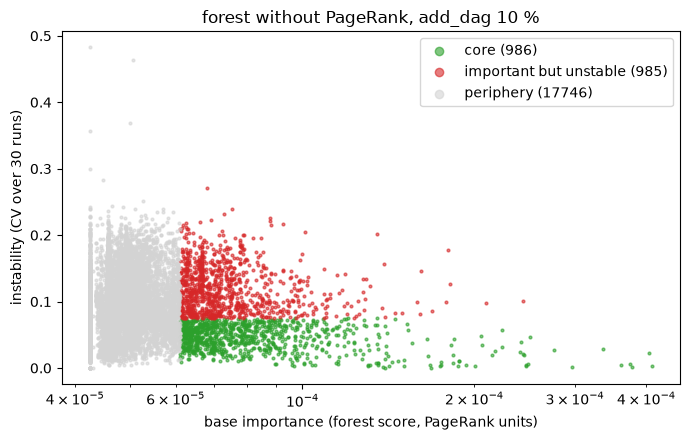

In [12]:
base = analysis.load_base_scores()
m, setting = 'rf_without_pagerank', ('add_dag', 0.10)
cv = cvs[setting][m]
ranks = ranking.to_ranking(base[m])
roles, _ = core.node_roles_within_important(ranks, cv)
colors = {'core': 'tab:green', 'important but unstable': 'tab:red', 'periphery': 'lightgray'}
fig, ax = plt.subplots(figsize=(7, 4.5))
for role, color in colors.items():
    sel = roles == role
    ax.scatter(base[m][sel], cv[sel], s=4, c=color, label=f'{role} ({sel.sum()})', alpha=0.6)
ax.set_xscale('log'); ax.set_xlabel('base importance (forest score, PageRank units)')
ax.set_ylabel('instability (CV over 30 runs)'); ax.legend(markerscale=3)
ax.set_title('forest without PageRank, add_dag 10 %')
plt.tight_layout(); fig.savefig(analysis.TABLES_DIR.parent / 'importance_vs_cv.png', dpi=120); plt.show()

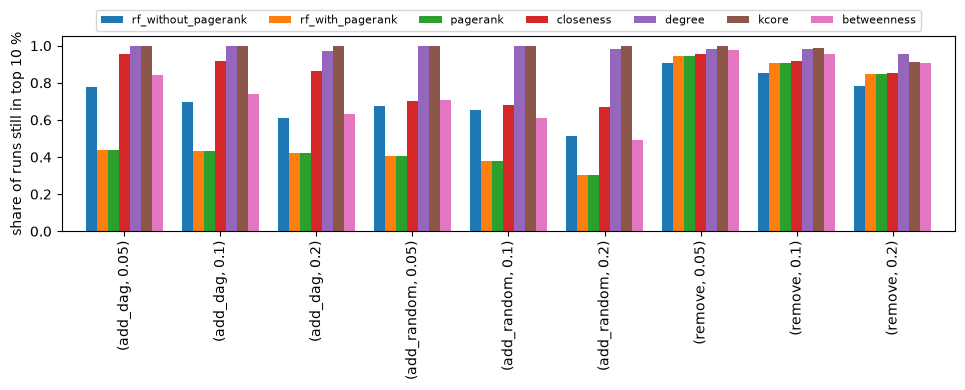

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
show('important_stay_in_top').T.plot.bar(ax=ax, width=0.8)
ax.set_ylabel('share of runs still in top 10 %'); ax.set_xlabel('')
ax.legend(fontsize=8, ncol=7, loc='lower center', bbox_to_anchor=(0.5, 1.0)); plt.tight_layout()
fig.savefig(analysis.TABLES_DIR.parent / 'top10_retention.png', dpi=120); plt.show()